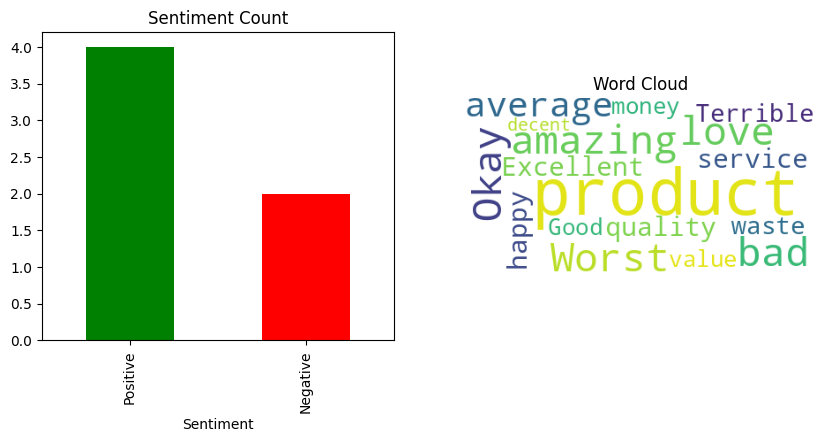

                           Review Sentiment
0   I love this product, amazing!  Positive
1        Worst product, very bad.  Negative
2  Okay product, average quality.  Positive
3  Excellent service, very happy.  Positive
4       Terrible, waste of money.  Negative
5     Good value, decent product.  Positive


In [6]:
# !pip install textblob wordcloud
import pandas as pd
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

# 1. Data
reviews = [
    "I love this product, amazing!",
    "Worst product, very bad.",
    "Okay product, average quality.",
    "Excellent service, very happy.",
    "Terrible, waste of money.",
    "Good value, decent product."
]
df = pd.DataFrame(reviews, columns=['Review'])

# 2. Sentiment - Positive/Negative/Neutral
def get_sentiment(text):
    score = TextBlob(text).sentiment.polarity
    if score > 0: return 'Positive'
    elif score < 0: return 'Negative'
    else: return 'Neutral'

df['Sentiment'] = df['Review'].apply(get_sentiment)

# 3. CSV Save
df.to_csv('reviews.csv', index=False)

# 4. Graph - Ekach image madhe 2 graph
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

df['Sentiment'].value_counts().plot(kind='bar', ax=axes[0], color=['green','red','gray'])
axes[0].set_title('Sentiment Count')

all_text = " ".join(df['Review'])
WordCloud(background_color='white').generate(all_text)
axes[1].imshow(WordCloud(background_color='white').generate(all_text))
axes[1].axis('off')
axes[1].set_title('Word Cloud')

plt.savefig('Sentiment_Result.png')
plt.show()

print(df)